In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df=pd.read_csv('/content/drive/MyDrive/student-mat.csv',sep=';')
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
df.shape

(395, 33)

In [5]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [6]:
df.isnull().sum()

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


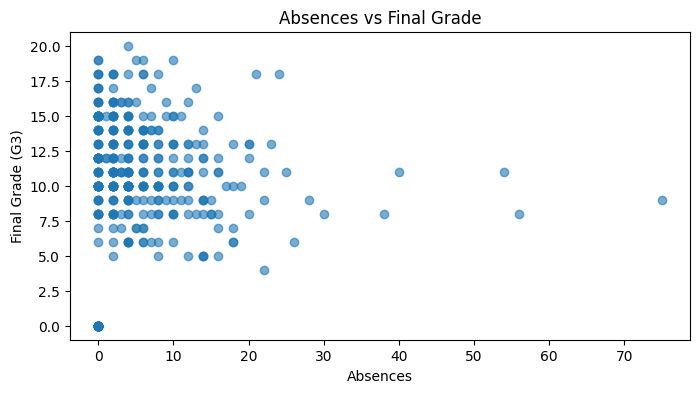

In [7]:
plt.figure(figsize=(8,4) )
plt.scatter(x=df['absences'],y=df['G3'],alpha=0.6)
plt.xlabel('Absences')
plt.ylabel('Final Grade (G3)')
plt.title('Absences vs Final Grade')
plt.show()

### **Finding Relationship between absences and G3**

- Correlation -1 ke qareeb → Strong negative relationship
- Correlation 0 ke qareeb → Weak ya no linear relationship
- Correlation +1 ke qareeb → Strong positive relationship

In [8]:
print("Relationship between absences and G3 ",df['absences'].corr(df['G3']))
print("Relationship between studytime and G3 ",df['studytime'].corr(df['G3']))

Relationship between absences and G3  0.03424731615006931
Relationship between studytime and G3  0.09781968965319626


### **Correlation between G3 and other columns**

Low correlation means that linear regression cant be implemented

In [9]:
df.corr(numeric_only=True)['G3'].sort_values(ascending=False)

,G3
G3,1.000000
G2,0.904868
G1,0.801468
Medu,0.217147
Fedu,0.152457
studytime,0.097820
famrel,0.051363
absences,0.034247
freetime,0.011307
Walc,-0.051939


To implement simple linear regression we will select only one feature because in simple linear regression we only find a regression between only one feature

In [10]:
x=df[['G2']]
y=df[['G3']]

In [11]:
x.shape

(395, 1)

In [12]:
y.shape

(395, 1)

In [13]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [14]:
print("X_train ",x_train.shape)
print("X_test ",x_test.shape)
print("y_train ",y_train.shape)
print("y_test ",y_test.shape)

X_train  (316, 1)
X_test  (79, 1)
y_train  (316, 1)
y_test  (79, 1)


In [15]:
from sklearn.linear_model import LinearRegression
lnr=LinearRegression()

Fitting Regression Line
This will calculate regression line from training data
y=mx+c

In [16]:
lnr.fit(x_train,y_train)

LinearRegression()

In [17]:
print("Slope: ",lnr.coef_)
print("Intercept: ",lnr.intercept_)

Slope:  [[1.1096259]]
Intercept:  [-1.49367332]


### **Making predictions**

In [18]:
y_pred=lnr.predict(x_test)
y_pred_dataframe=pd.DataFrame(y_pred,columns=['Predicted Values of G3'])
y_pred_dataframe

,Predicted Values of G3
0,7.383334
1,11.821837
2,4.054456
3,8.492960
4,8.492960
...,...
74,10.712212
75,5.164082
76,8.492960
77,14.041089


Comparing actual vs predicted values

In [19]:
print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)

y_test shape: (79, 1)
y_pred shape: (79, 1)


In [20]:
results = pd.DataFrame({
    'Actual Grades': y_test.to_numpy().ravel(),
    'Predicted Grades': np.asarray(y_pred).ravel()
})
results.head(10)

,Actual Grades,Predicted Grades
0,10,7.383334
1,12,11.821837
2,5,4.054456
3,10,8.492960
4,9,8.492960
5,13,12.931463
6,18,18.479593
7,6,6.273708
8,0,7.383334
9,14,12.931463


### **Residual Error Calculation**

y=y(actual)-y_predicted

Positive error → Model ne actual grade se kam predict kiya.

Negative error → Model ne actual grade se zyada predict kiya.

Zero error → Prediction bilkul correct hai.

In [25]:
results['error']=results['Actual Grades']-results['Predicted Grades']
results.head(10)

,Actual Grades,Predicted Grades,error
0,10,7.383334,2.616666
1,12,11.821837,0.178163
2,5,4.054456,0.945544
3,10,8.492960,1.507040
4,9,8.492960,0.507040
5,13,12.931463,0.068537
6,18,18.479593,-0.479593
7,6,6.273708,-0.273708
8,0,7.383334,-7.383334
9,14,12.931463,1.068537


Positive Error = Underprediction

Model ne actual value se kam predict kiya.

Negative Error = Overprediction

Model ne actual value se zyada predict kiya.

Zero Error = Perfect Prediction

Model ki predicted value actual value ke equal hai.

In [28]:
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(y_test,y_pred)
print("MAE: ",mae)

MAE:  1.2086747008196355


In [30]:
from sklearn.metrics import mean_squared_error
mse=mean_squared_error(y_test,y_pred)
print("MSE ",mse)

MSE  4.216183766505532


In [31]:
rmse=np.sqrt(mse)
print("RMSE: ",rmse)

RMSE:  2.0533347916269116


### **R2 Score**

In [33]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)
print("R2 Score: ",r2)
accuracy=r2*100
print("Accuracy: ",accuracy)

R2 Score:  0.794383123755501
Accuracy:  79.4383123755501


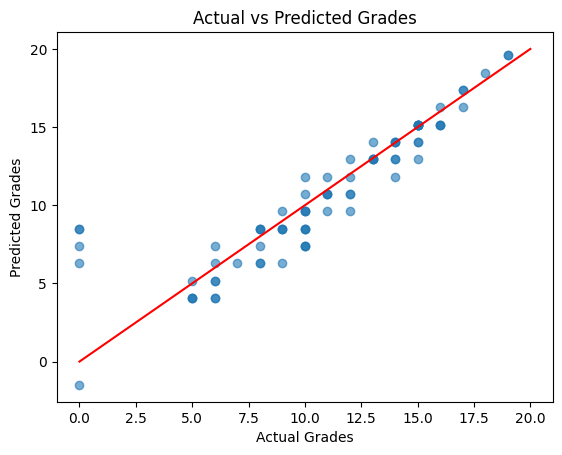

In [23]:
plt.scatter(y_test,y_pred,alpha=0.6)
plt.plot([0,20],[0,20],color='red')
plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title('Actual vs Predicted Grades')
plt.show()

### **Residual Graph**

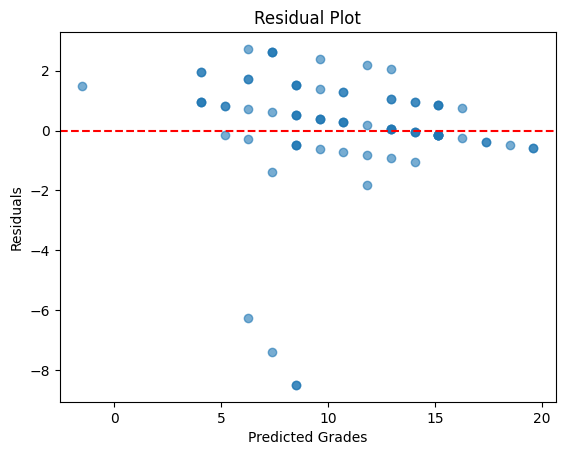

In [25]:
residuals = y_test.to_numpy().ravel() - y_pred.ravel()
plt.scatter(y_pred.ravel(), residuals, alpha=0.6)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Grades')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.show()

### **Detecting Outliers**

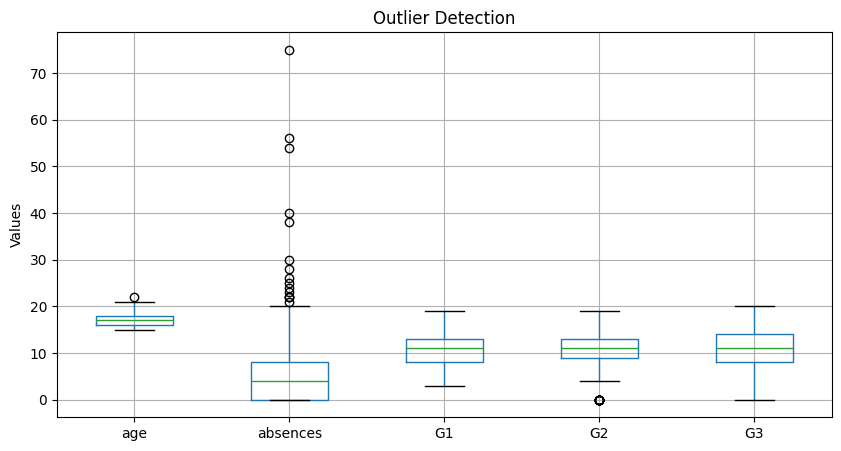

In [ ]:
import matplotlib.pyplot as plt
columns=['age','absences','G1','G2','G3']
df[columns].boxplot(figsize=(10,5))
plt.title("Outlier Detection")
plt.ylabel('Values')
plt.show()

In [ ]:
print(df['absences'])
print('Min absences ',df['absences'].min())
print("Max absences ",df['absences'].max())

0       6
1       4
2      10
3       2
4       4
       ..
390    11
391     3
392     3
393     0
394     5
Name: absences, Length: 395, dtype: int64
Min absences  0
Max absences  75


In [ ]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [ ]:
import matplotlib.pyplot as plt

### **Removing Outliers in Absences column**

In [ ]:
Q1=df['absences'].quantile(0.25)
print(Q1)
Q3=df['absences'].quantile(0.75)
print(Q3)

# Interquartile range
IQR=Q3-Q1
print("Interquartile range ",IQR)

0.0
8.0
Interquartile range  8.0


Calculating Lower and Upper Boundaries

In [ ]:
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
print(f'lower boundary {lower_bound}')
print(f'upper boundary {upper_bound}')

lower boundary -12.0
upper boundary 20.0


In [ ]:
outliers=df[
    (df['absences']<lower_bound) |
    (df['absences']>upper_bound)
]

print(f'Total outliers {len(outliers)}')
print(f"Upper bound {upper_bound}")

Total outliers 15
Upper bound 20.0


### **Copying Outliers**

In [ ]:
df_clean=df[
    (df['absences']>=lower_bound) &
    (df['absences']<=upper_bound)
].copy()
df_clean

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


In [ ]:
print(f"Original Dataset shape {df.shape}")
print(f"Cleaned Dataset shape {df_clean.shape}")
# 15 outlier rows have been removed

Original Dataset shape (395, 33)
Cleaned Dataset shape (380, 33)


0.03424731615006931
